# 02 · Train the models

**Goal:** compare 3 models on the Khmer consonant data and save the best ones.

| # | Model | Idea |
|---|---|---|
| 1 | Logistic regression | Draws straight lines between classes in pixel space. The simplest baseline. |
| 2 | Random forest | Many decision trees vote. A non-linear baseline. |
| 3 | Simple CNN | Learns strokes and shapes from the image. Our main model. |

**Rules we follow**
* The **test writers are never used here.** We only use train + val writers (called the *dev set*). The test set is used once, in `03_evaluate.ipynb`.
* We have few writers, so one validation score is noisy. We use **5-fold cross-validation grouped by writer**: in every fold, the writers in the held-out part never appear in the training part.
* We compare models by the **mean accuracy over the 5 folds**.

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import data as D
from src.train import train_model, predict_probs, get_device
import torch

SEED, EPOCHS, FOLDS = 42, 40, 5   # 40 epochs at learning rate 3e-4 (see src/train.py)
(ROOT / "models").mkdir(exist_ok=True); (ROOT / "reports").mkdir(exist_ok=True)
print("device:", get_device())

device: cpu


## 1. Load the data and set the test set aside

`X` has one row per image (64×64 pixels, ink = 1). `dev` = train + val writers. We never look at the test rows.

In [2]:
X_all, df = D.load_all()
dev = (df.split != "test").values
X, y, writers = X_all[dev], df.label_id.values[dev], df.writer_id.values[dev]
X_flat = X.reshape(len(X), -1)          # for the classic models: 64*64 = 4096 pixel features per image
print(f"dev set: {len(X)} images, {len(set(writers))} writers   |   test set (not used here): {(~dev).sum()} images")

cv = GroupKFold(n_splits=FOLDS)
folds = list(cv.split(X, y, groups=writers))
for i, (tr, te) in enumerate(folds):
    print(f"fold {i}: train {len(tr)} imgs / {len(set(writers[tr]))} writers   held-out {len(te)} imgs / {len(set(writers[te]))} writers")

dev set: 1056 images, 25 writers   |   test set (not used here): 132 images
fold 0: train 825 imgs / 21 writers   held-out 231 imgs / 4 writers
fold 1: train 825 imgs / 19 writers   held-out 231 imgs / 6 writers
fold 2: train 858 imgs / 20 writers   held-out 198 imgs / 5 writers
fold 3: train 858 imgs / 20 writers   held-out 198 imgs / 5 writers
fold 4: train 858 imgs / 20 writers   held-out 198 imgs / 5 writers


## 2. Baselines: logistic regression and random forest

`GridSearchCV` tries a few settings and keeps the best by cross-validation. We pass `groups=writers`, so a writer never appears on both sides.

In [3]:
results = []   # (model, fold, accuracy)

def run_grid(name, estimator, grid):
    t = time.time()
    gs = GridSearchCV(estimator, grid, cv=cv, scoring="accuracy", n_jobs=-1, refit=False)
    gs.fit(X_flat, y, groups=writers)
    best = gs.best_index_
    fold_scores = [gs.cv_results_[f"split{i}_test_score"][best] for i in range(FOLDS)]
    for i, s in enumerate(fold_scores):
        results.append((name, i, s))
    print(f"{name:20} best settings {gs.best_params_}   CV accuracy {np.mean(fold_scores):.3f} ± {np.std(fold_scores):.3f}   ({time.time()-t:.0f}s)")
    return gs.best_params_

best_lr = run_grid("Logistic regression", LogisticRegression(max_iter=2000), {"C": [0.01, 0.1, 1, 10]})
best_rf = run_grid("Random forest", RandomForestClassifier(n_estimators=300, random_state=SEED), {"max_depth": [None, 20, 40]})

Logistic regression  best settings {'C': 0.1}   CV accuracy 0.650 ± 0.025   (13s)
Random forest        best settings {'max_depth': 20}   CV accuracy 0.568 ± 0.024   (9s)


## 3. CNN, with and without augmentation

Same 5 folds. Every fold trains a CNN from scratch for `EPOCHS` epochs and scores the held-out writers with the **last epoch** (we don't pick the best epoch on held-out data, that would be cheating).
We compare:
* **CNN, no augmentation**
* **CNN + augmentation** (random small rotation, shift, zoom, and sometimes thicker strokes)

In [4]:
def cv_cnn(name, aug):
    t = time.time(); accs = []
    for i, (tr, te) in enumerate(folds):
        model, hist = train_model(X[tr], y[tr], X[te], y[te], epochs=EPOCHS, aug=aug, seed=SEED, verbose=False)
        acc = float((predict_probs(model, X[te]).argmax(1) == y[te]).mean())
        accs.append(acc); results.append((name, i, acc))
    print(f"{name:20} CV accuracy {np.mean(accs):.3f} ± {np.std(accs):.3f}   folds {np.round(accs, 3)}   ({time.time()-t:.0f}s)")
    return np.mean(accs)

acc_noaug = cv_cnn("CNN (no augment)", aug=False)
acc_aug   = cv_cnn("CNN + augment", aug=True)

CNN (no augment)     CV accuracy 0.837 ± 0.022   folds [0.831 0.818 0.818 0.879 0.838]   (430s)
CNN + augment        CV accuracy 0.831 ± 0.037   folds [0.818 0.788 0.803 0.889 0.859]   (421s)


## 4. Compare

                      mean    std
model                            
CNN (no augment)     0.837  0.025
CNN + augment        0.831  0.042
Logistic regression  0.650  0.028
Random forest        0.568  0.027
chance level = 0.030


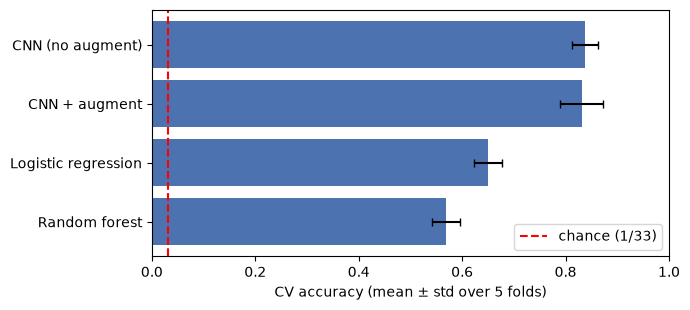

Final CNN will use augmentation: False


In [5]:
res = pd.DataFrame(results, columns=["model", "fold", "accuracy"])
summary = res.groupby("model").accuracy.agg(["mean", "std"]).sort_values("mean", ascending=False).round(3)
summary.to_csv(ROOT / "reports" / "cv_results.csv")
print(summary)
print(f"chance level = {1/33:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(summary.index[::-1], summary["mean"][::-1], xerr=summary["std"][::-1], color="#4C72B0", capsize=3)
ax.axvline(1/33, color="red", ls="--", label="chance (1/33)"); ax.set_xlabel("CV accuracy (mean ± std over 5 folds)")
ax.set_xlim(0, 1); ax.legend(); plt.tight_layout(); plt.savefig(ROOT / "reports" / "cv_comparison.png", dpi=150); plt.show()

USE_AUG = acc_aug >= acc_noaug
print("Final CNN will use augmentation:", USE_AUG)

## 5. Training curves (overfitting check)

One run: train on the **train** writers, watch the **val** writers. If train accuracy keeps going up but val accuracy stops, the model is memorising.

epoch  1  train_loss 3.394  train_acc 0.084  val_loss 3.282  val_acc 0.164
epoch  5  train_loss 1.991  train_acc 0.426  val_loss 1.411  val_acc 0.745
epoch 10  train_loss 1.174  train_acc 0.654  val_loss 0.633  val_acc 0.855
epoch 15  train_loss 0.793  train_acc 0.756  val_loss 0.411  val_acc 0.915
epoch 20  train_loss 0.589  train_acc 0.829  val_loss 0.302  val_acc 0.939
epoch 25  train_loss 0.498  train_acc 0.852  val_loss 0.216  val_acc 0.982
epoch 30  train_loss 0.416  train_acc 0.864  val_loss 0.191  val_acc 0.964
epoch 35  train_loss 0.403  train_acc 0.879  val_loss 0.174  val_acc 0.976
epoch 40  train_loss 0.358  train_acc 0.879  val_loss 0.172  val_acc 0.958


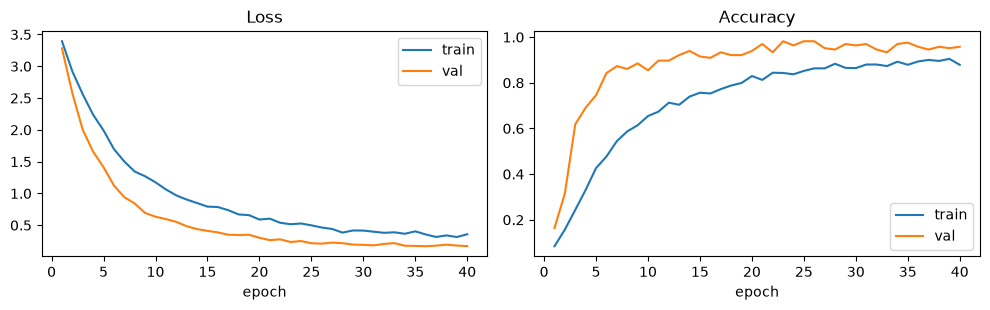

In [6]:
tr_mask, va_mask = (df.split[dev] == "train").values, (df.split[dev] == "val").values
_, hist = train_model(X[tr_mask], y[tr_mask], X[va_mask], y[va_mask], epochs=EPOCHS, aug=USE_AUG, seed=SEED, verbose=True)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hist.epoch, hist.train_loss, label="train"); ax[0].plot(hist.epoch, hist.val_loss, label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist.epoch, hist.train_acc, label="train"); ax[1].plot(hist.epoch, hist.val_acc, label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(ROOT / "reports" / "training_curves.png", dpi=150); plt.show()

## 6. Train the final models and save them

Final models are trained on **all dev writers** (train + val) with the best settings, then saved to `models/`. `03_evaluate.ipynb` loads them and tests on the test writers once.

In [7]:
final_cnn, _ = train_model(X, y, epochs=EPOCHS, aug=USE_AUG, seed=SEED, verbose=False)
torch.save(final_cnn.state_dict(), ROOT / "models" / "cnn.pt")

lr = LogisticRegression(max_iter=2000, **best_lr).fit(X_flat, y)
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, **best_rf).fit(X_flat, y)
joblib.dump(lr, ROOT / "models" / "logreg.joblib", compress=3)
joblib.dump(rf, ROOT / "models" / "forest.joblib", compress=3)

meta = {"epochs": EPOCHS, "augment": bool(USE_AUG), "seed": SEED, "logreg": best_lr, "forest": best_rf,
        "trained_on": f"{len(X)} images from {len(set(writers))} writers (train + val)",
        "cv_accuracy": {m: float(v) for m, v in summary["mean"].items()}}
(ROOT / "models" / "meta.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))
for f in sorted((ROOT / "models").iterdir()):
    print(f"{f.name:15} {f.stat().st_size/1e6:.1f} MB")

{
  "epochs": 40,
  "augment": false,
  "seed": 42,
  "logreg": {
    "C": 0.1
  },
  "forest": {
    "max_depth": 20
  },
  "trained_on": "1056 images from 25 writers (train + val)",
  "cv_accuracy": {
    "CNN (no augment)": 0.837,
    "CNN + augment": 0.831,
    "Logistic regression": 0.65,
    "Random forest": 0.568
  }
}
cnn.pt          4.6 MB
forest.joblib   5.8 MB
logreg.joblib   0.3 MB
meta.json       0.0 MB


## Next
Open `03_evaluate.ipynb`. It tests these saved models on the held-out **test writers** (once), and makes the confusion matrix and error analysis.